# A/B-тест: положение гейта в мобильной игре Cookie Cats

Гейт это уровень, на котором игрока просят подождать или заплатить. Контроль: гейт
на 30-м уровне. Тест: на 40-м. Гипотеза продукта - отодвинутый гейт повышает удержание.

| Метрика | Роль |
|---|---|
| `retention_7` | решающая |
| `retention_1` | негативный контроль |
| `sum_gamerounds` | диагностическая |

Решающее правило: внедряем изменение при приросте `retention_7`
не менее +1 п.п. абсолютных.

---

### Вывод

> **Гейт не переносить.** `retention_7`: 19.02% → 18.20%, эффект −0.82 п.п.,
> CI95 [−1.33; −0.31] п.п., p = 0.0016. Гипотеза «эффект достигает порога +1 п.п.»
> отвергнута (p = 1e-12), весь интервал ниже нуля.
>
> **Оценка смещена.** SRM: контроль 49.56% при ожидаемых 50%, p = 0.0086.
> На негативном контроле сдвиг того же знака: −0.59 п.п., p = 0.074 - незначимо,
> но и ниже порога чувствительности этой метрики (0.93 п.п.), так что отсутствие
> различия групп из него не следует. Если сдвиг на day-1 отражает состав групп,
> а не эффект, то −0.82 п.п. завышает вред; величину считаем ориентиром,
> а не измерением. Знак вывода устойчив, в плюс не ушла ни одна метрика.

---

### Содержание

1. Данные
2. Метрики и решающее правило
3. Мощность
4. Санити-чеки: SRM, A/A, тяжёлый хвост
5. Анализ: главная метрика, тест против порога, негативный контроль, множественность
6. Подглядывание
7. Решение

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
import statsmodels
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import mannwhitneyu, bootstrap
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize, proportions_ztest


warnings.simplefilter("ignore", FutureWarning)
warnings.simplefilter("ignore", DeprecationWarning)

SEED = 42
ALPHA = 0.05          # уровень значимости для решающей метрики
POWER = 0.80          # требуемая мощность
ALPHA_SRM = 0.01      # для SRM порог строже обычного; разбор в разделе 4.1
CONTROL, TREAT = "gate_30", "gate_40"


RNG_AA = np.random.default_rng(SEED)        # A/A-перестановки
RNG_BOOT = np.random.default_rng(SEED + 1)  # бутстрап разницы долей
RNG_PEEK = np.random.default_rng(SEED + 2)  # симуляция подглядывания

plt.rcParams.update({
    "figure.dpi": 120, "font.size": 9, "axes.grid": True,
    "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False,
})
BLUE, ORANGE, GREY = "#2b6cb0", "#dd6b20", "#718096"

pd.set_option("display.width", 140)
# Доли печатаем с четырьмя знаками, крупные числа (счётчики) без дробной части
pd.set_option("display.float_format",
              lambda v: f"{v:,.4f}" if abs(v) < 1000 else f"{v:,.0f}")


def ru(n, digits=0):
    """Число с пробелом как разделителем разрядов."""
    return f"{n:,.{digits}f}".replace(",", " ")


print("python     ", ".".join(map(str, __import__("sys").version_info[:3])))
for mod in (np, pd, scipy, statsmodels, matplotlib):
    print(f"{mod.__name__:<11}", mod.__version__)

python      3.8.5
numpy       1.24.4
pandas      2.0.3
scipy       1.10.1
statsmodels 0.12.0
matplotlib  3.3.2


## 1. Данные

Cookie Cats, 90 189 игроков. Колонки: `userid`, `version`, `sum_gamerounds`
(раундов за время наблюдения), `retention_1`, `retention_7`.
Источник: https://www.kaggle.com/datasets/yufengsui/mobile-games-ab-testing

Проверяем схему, отсутствие пропусков и уникальность `userid`.

Состав датасета задаёт рамку работы: объём выборки зафиксирован, даты установки,
номера уровня и денежных метрик нет.

In [2]:
DATA_FILE = Path("cookie_cats.csv")

if not DATA_FILE.is_file():
    raise FileNotFoundError(
        f"Положите {DATA_FILE.name} рядом с ноутбуком "
        "(Kaggle: yufengsui/mobile-games-ab-testing)"
    )

df = pd.read_csv(DATA_FILE)


for col in ("retention_1", "retention_7"):
    s = df[col]
    if s.dtype == object:
        mapped = s.str.strip().str.lower().map({"true": True, "false": False,
                                                "1": True, "0": False})
        if mapped.isna().any():
            raise ValueError(f"{col}: не удалось распознать значения "
                             f"{sorted(s[mapped.isna()].unique())[:5]}")
        df[col] = mapped.astype(bool)
    else:
        df[col] = s.astype(bool)

assert set(df["version"]) == {CONTROL, TREAT}, "неожиданные значения version"
assert not df[["sum_gamerounds", "retention_1", "retention_7"]].isna().any().any()


n_dup = int(df["userid"].duplicated().sum())
print("Дубликатов userid:", n_dup, "-> ок" if n_dup == 0 else "-> ВНИМАНИЕ, см. ниже")
if n_dup:
    print("  Наблюдения не независимы, интервалы будут занижены.")
    print("  Перед выводами нужно разобраться с природой дубликатов.")

print("Игроков:", ru(len(df)))
print(df["version"].value_counts().to_string())
df.head()

Дубликатов userid: 0 -> ок
Игроков: 90 189
version
gate_40    45489
gate_30    44700


,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


In [3]:
METRICS = ["retention_1", "retention_7", "sum_gamerounds"]

overview = (df.groupby("version")[METRICS]
              .agg(["mean", "median", "count"])
              .T)
overview

version                gate_30  gate_40
retention_1    mean     0.4482   0.4423
               median   0.0000   0.0000
               count    44,700   45,489
retention_7    mean     0.1902   0.1820
               median   0.0000   0.0000
               count    44,700   45,489
sum_gamerounds mean    52.4563  51.2988
               median  17.0000  16.0000
               count    44,700   45,489

## 2. Метрики и решающее правило

**`retention_7` - решающая.** Эффект гейта проявляется на горизонте недели.

**Порог: +1 п.п. абсолютных.** Внешнее допущение: юнит-экономики в данных нет.

**Правило: внедряем изменение при приросте не меньше порога.** Правило отвергается
не нулём, а значениями ниже +1 п.п., поэтому главную метрику проверяем дважды:
против нуля и против порога (раздел 5.1).

**`retention_1` - негативный контроль.** Медиана `sum_gamerounds` за всё время
наблюдения - 16-17 раундов, а раундов за первые сутки не больше, чем за весь период.
Если считать число раундов приближением к пройденным уровням, медианный игрок
до 30-го уровня в первые сутки не доходит и гейта не встречает. Номера уровня
в данных нет, поэтому это допущение, а не измерение.

При таком допущении эффекта на day-1 быть не должно, и сдвиг указывал бы
на различие групп, а не на продукт.

**`sum_gamerounds` - диагностическая.** Гейт прямо ограничивает прохождение уровней,
поэтому раунды - следствие воздействия, а не независимая страховка.

## 3. Мощность

Объём выборки задан датасетом. Считаем, какой эффект он позволяет поймать
при мощности 80%, чтобы знать, не объясняется ли незначимость нехваткой наблюдений.
База берётся из контрольной группы этого же теста, поэтому для планирования
выборки расчёт непригоден.

In [4]:
MDE_ABS = 0.01        # объявленный порог окупаемости, +1 п.п. абсолютных

base = df.loc[df["version"] == CONTROL, "retention_7"].mean()
n_control = int((df["version"] == CONTROL).sum())
n_treat = int((df["version"] == TREAT).sum())

power_solver = NormalIndPower()
h_target = proportion_effectsize(base + MDE_ABS, base)
n_needed = power_solver.solve_power(effect_size=h_target, alpha=ALPHA,
                                    power=POWER, ratio=1.0, alternative="two-sided")

print(f"Базовое удержание на 7-й день (контроль): {base:.4f}")
print(f"Порог окупаемости: +{MDE_ABS:.1%} абсолютных ({MDE_ABS / base:.1%} относительных)")
print("Нужно на группу:", ru(n_needed))
print("Фактически:     ", ru(n_control), "и", ru(n_treat))

Базовое удержание на 7-й день (контроль): 0.1902
Порог окупаемости: +1.0% абсолютных (5.3% относительных)
Нужно на группу: 24 657
Фактически:      44 700 и 45 489


In [5]:
def detectable_effect(base_rate, alpha=ALPHA, power=POWER):
    """Минимальный эффект, обнаруживаемый при заданной мощности. В долях."""
    h = power_solver.solve_power(effect_size=None, nobs1=n_control, alpha=alpha,
                                 power=power, ratio=n_treat / n_control,
                                 alternative="two-sided")
    return np.sin(h / 2 + np.arcsin(np.sqrt(base_rate))) ** 2 - base_rate


base_r1 = df.loc[df["version"] == CONTROL, "retention_1"].mean()
mde_real = detectable_effect(base)
mde_r1 = detectable_effect(base_r1)

print(f"retention_7: база {base:.4f}, детектируемый эффект {mde_real * 100:+.2f} п.п. "
      f"({mde_real / base:+.1%} относительных)")
print(f"retention_1: база {base_r1:.4f}, детектируемый эффект {mde_r1 * 100:+.2f} п.п. "
      f"({mde_r1 / base_r1:+.1%} относительных)")
print("\nЧувствительность зависит от базового уровня: при доле около 0.5 дисперсия на наблюдение максимальна, поэтому тот же объём выборки ловит больший эффект.")

retention_7: база 0.1902, детектируемый эффект +0.74 п.п. (+3.9% относительных)
retention_1: база 0.4482, детектируемый эффект +0.93 п.п. (+2.1% относительных)

Чувствительность зависит от базового уровня: при доле около 0.5 дисперсия на наблюдение максимальна, поэтому тот же объём выборки ловит больший эффект.


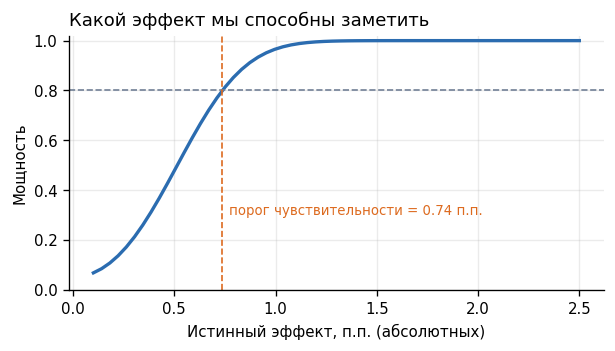

In [6]:
# Кривая мощности: как вероятность заметить эффект зависит от его величины
lifts = np.linspace(0.001, 0.025, 60)
powers = [power_solver.power(effect_size=proportion_effectsize(base + d, base),
                             nobs1=n_control, alpha=ALPHA, ratio=n_treat / n_control,
                             alternative="two-sided") for d in lifts]

fig, ax = plt.subplots(figsize=(5.2, 3.0))
ax.plot(lifts * 100, powers, color=BLUE, lw=2)
ax.axhline(POWER, color=GREY, ls="--", lw=1)
ax.axvline(mde_real * 100, color=ORANGE, ls="--", lw=1)
ax.annotate(f"порог чувствительности = {mde_real * 100:.2f} п.п.", xy=(mde_real * 100, 0.3),
            xytext=(4, 0), textcoords="offset points", color=ORANGE, fontsize=8)
ax.set_xlabel("Истинный эффект, п.п. (абсолютных)")
ax.set_ylabel("Мощность")
ax.set_title("Какой эффект мы способны заметить", loc="left")
ax.set_ylim(0, 1.02)
fig.tight_layout()
plt.show()

**Вывод.** База `retention_7` - 19.02%. Под порог +1 п.п. хватило бы 24 657 на группу,
фактически 44 700 и 45 489; детектируемый эффект - 0.74 п.п., ниже порога. Для главной
метрики объёма достаточно.

Для `retention_1` при базе 44.8% тот же объём ловит только 0.93 п.п.: чем ближе доля
к 0.5, тем больше дисперсия на наблюдение. Для `sum_gamerounds` с тяжёлым хвостом
расчёт в этой параметризации неприменим вовсе. Поэтому вывод о достаточности объёма
относится к `retention_7`, а не ко всем метрикам.

## 4. Санити-чеки

### 4.1 SRM

Хи-квадрат на соответствие фактического сплита ожидаемому 50/50. Печатаем p
и смотрим его против двух порогов: 0.01 и принятого в продакшене 0.001. Порог здесь
прямо определяет вердикт, поэтому ориентируемся не только на него, но и на величину
отклонения.

In [7]:
counts = df["version"].value_counts().reindex([CONTROL, TREAT])
expected = np.full(2, counts.sum() / 2)
chi2_srm, p_srm = stats.chisquare(counts.to_numpy(), expected)

print(f"{CONTROL}:", ru(counts[CONTROL]))
print(f"{TREAT}:", ru(counts[TREAT]))
print(f"Доля контроля: {counts[CONTROL] / counts.sum():.4f}")
print(f"chi2 = {chi2_srm:.3f}, p = {p_srm:.4f}")
print(f"При пороге {ALPHA_SRM}: "
      f"{'перекос значим' if p_srm < ALPHA_SRM else 'перекос незначим'}")
print(f"При продакшен-пороге 0.001: "
      f"{'перекос значим' if p_srm < 0.001 else 'перекос незначим'}")

gate_30: 44 700
gate_40: 45 489
Доля контроля: 0.4956
chi2 = 6.902, p = 0.0086
При пороге 0.01: перекос значим
При продакшен-пороге 0.001: перекос незначим


**Вывод.** Контроль 49.56%, p = 0.0086. При пороге 0.01 отклонение значимо,
при 0.001 - нет, то есть вердикт определяется выбором порога, а сама величина
отклонения мала: 0.44 п.п. от половины.

Трактуем как предупреждение, не как блокирующий сигнал, и ищем независимый след
в негативном контроле (5.2). Проверки процедуры дальше делаем при фактических
размерах групп.

### 4.2 A/A

5000 случайных перестановок меток при фактических размерах групп, z-критерий
на каждой. Проверяем равномерность p-value и долю срабатываний при 5%.

Перестановка покрывает реализацию критерия и адекватность нормальной аппроксимации;
распределение пользователей по группам - нет.

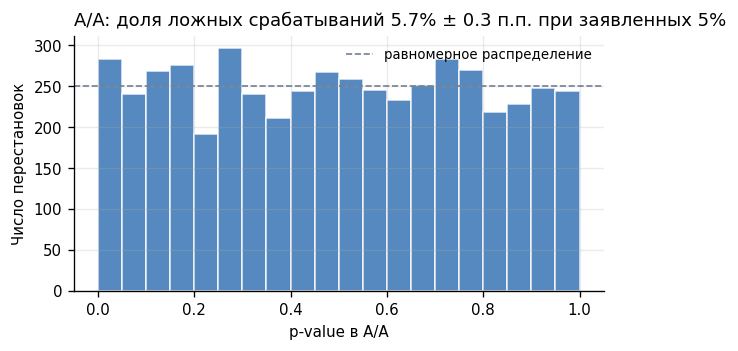

Доля p < 0.05: 0.057 ± 0.003 (ожидаем ~0.05)
Тест Колмогорова-Смирнова на равномерность: p = 0.255
Перестановок: 5 000


In [8]:
N_PERM = 5000
y_aa = df["retention_7"].to_numpy()
total = len(y_aa)

pvals_aa = np.empty(N_PERM)
for i in range(N_PERM):
    idx = RNG_AA.permutation(total)
    a_aa, b_aa = y_aa[idx[:n_control]], y_aa[idx[n_control:]]
    _, pvals_aa[i] = proportions_ztest([a_aa.sum(), b_aa.sum()], [len(a_aa), len(b_aa)])

fpr_aa = (pvals_aa < ALPHA).mean()
fpr_se = np.sqrt(fpr_aa * (1 - fpr_aa) / N_PERM)      # точность самой оценки
ks_p = stats.kstest(pvals_aa, "uniform").pvalue

fig, ax = plt.subplots(figsize=(5.2, 3.0))
ax.hist(pvals_aa, bins=20, range=(0, 1), color=BLUE, alpha=0.8, edgecolor="white")
ax.axhline(N_PERM / 20, color=GREY, ls="--", lw=1, label="равномерное распределение")
ax.set_xlabel("p-value в A/A")
ax.set_ylabel("Число перестановок")
ax.set_title(f"A/A: доля ложных срабатываний {fpr_aa:.1%} "
             f"± {fpr_se * 100:.1f} п.п. при заявленных {ALPHA:.0%}", loc="left")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

print(f"Доля p < {ALPHA}: {fpr_aa:.3f} ± {fpr_se:.3f} (ожидаем ~{ALPHA})")
print(f"Тест Колмогорова-Смирнова на равномерность: p = {ks_p:.3f}")
print(f"Перестановок: {ru(N_PERM)}")

**Вывод.** Равномерность не отвергается, доля срабатываний близка к 5% в пределах
погрешности оценки (±0.3 п.п. на 5000 перестановок). Критерий реализован верно.

### 4.3 Тяжёлый хвост в числе раундов

 userid version  sum_gamerounds
6390605 gate_30           49854
 871500 gate_30            2961
3271615 gate_40            2640
4832608 gate_30            2438
5346171 gate_40            2294

         все данные  без верхних 0.1%  медиана
version                                       
gate_30     52.4563           50.0921  17.0000
gate_40     51.2988           49.8099  16.0000

Доля игроков с 0 раундов: 4.43%


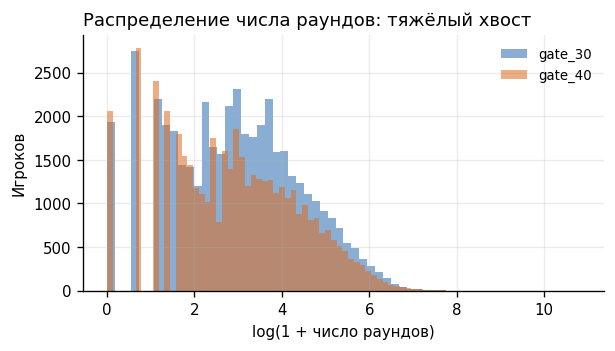

In [9]:
top = df.nlargest(5, "sum_gamerounds")[["userid", "version", "sum_gamerounds"]]
print(top.to_string(index=False))

cut = df["sum_gamerounds"].quantile(0.999)
trimmed = df[df["sum_gamerounds"] <= cut]

rounds_cmp = pd.DataFrame({
    "все данные": df.groupby("version")["sum_gamerounds"].mean(),
    "без верхних 0.1%": trimmed.groupby("version")["sum_gamerounds"].mean(),
    "медиана": df.groupby("version")["sum_gamerounds"].median(),
})
print()
print(rounds_cmp.to_string())
print(f"\nДоля игроков с 0 раундов: {(df['sum_gamerounds'] == 0).mean():.2%}")

fig, ax = plt.subplots(figsize=(5.2, 3.0))
for v, color in [(CONTROL, BLUE), (TREAT, ORANGE)]:
    vals = df.loc[df["version"] == v, "sum_gamerounds"]
    ax.hist(np.log1p(vals), bins=60, alpha=0.55, color=color, label=v)
ax.set_xlabel("log(1 + число раундов)")
ax.set_ylabel("Игроков")
ax.set_title("Распределение числа раундов: тяжёлый хвост", loc="left")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

In [10]:
g_control = df.loc[df["version"] == CONTROL, "sum_gamerounds"].to_numpy(float)
g_treat = df.loc[df["version"] == TREAT, "sum_gamerounds"].to_numpy(float)


_, p_guard_mw = mannwhitneyu(g_treat, g_control, alternative="two-sided")

# Бутстрап-интервалы: для медианы и для среднего (тест минус контроль).
# Отдельный генератор на каждый вызов чтобы результат не зависел от порядка ячеек.
def boot_ci(stat, seed):
    r = bootstrap((g_treat, g_control), stat, n_resamples=5000,
                  method="percentile", batch=100,
                  random_state=np.random.default_rng(seed))
    return r.confidence_interval

med_diff = np.median(g_treat) - np.median(g_control)
med_lo, med_hi = boot_ci(lambda x, y: np.median(x) - np.median(y), SEED + 10)

mean_diff = g_treat.mean() - g_control.mean()
mean_lo, mean_hi = boot_ci(lambda x, y: np.mean(x) - np.mean(y), SEED + 11)

print(f"Mann-Whitney p = {p_guard_mw:.4f}")
print(f"Разница медиан (тест - контроль):  {med_diff:+.1f}, CI95 [{med_lo:+.1f}; {med_hi:+.1f}]")
print(f"Разница средних (тест - контроль): {mean_diff:+.2f}, CI95 [{mean_lo:+.2f}; {mean_hi:+.2f}]")

Mann-Whitney p = 0.0502
Разница медиан (тест - контроль):  -1.0, CI95 [-1.0; +0.0]
Разница средних (тест - контроль): -1.16, CI95 [-4.04; +1.00]


**Вывод.** Медиана 16-17 раундов при среднем около 51, максимум 49 854 - среднее
определяется хвостом. Критерий - Манна-Уитни, неопределённость - бутстрап.

Результат на границе: p = 0.050, разница медиан −1 раунд. Порог не пройден,
но знак совпадает с удержанием.


## 5. Анализ

Доли: z-критерий и доверительный интервал на разницу.

Дисперсия в критерии и в интервале считается по-разному: объединённая доля
под нулевой гипотезой, отдельные доли для оценки разницы. Согласованность
проверяем бутстрапом.

In [11]:
def compare_proportions(data, metric, control=CONTROL, treat=TREAT, alpha=ALPHA):
    a = data.loc[data["version"] == control, metric].to_numpy()
    b = data.loc[data["version"] == treat, metric].to_numpy()
    pa, pb = a.mean(), b.mean()
    na, nb = len(a), len(b)
    diff = pb - pa                                     # эффект тестовой группы
    
    se = np.sqrt(pa * (1 - pa) / na + pb * (1 - pb) / nb)
    z = stats.norm.ppf(1 - alpha / 2)
    
    _, pval = proportions_ztest([b.sum(), a.sum()], [nb, na])
    return dict(metric=metric, control=pa, treat=pb, diff=diff,
                ci_low=diff - z * se, ci_high=diff + z * se,
                rel=diff / pa, p_value=pval)


def bootstrap_diff(data, metric, control=CONTROL, treat=TREAT,
                   n_boot=2000, alpha=ALPHA, rng=None):
    """Непараметрический бутстрап разницы средних — проверка, что формулы не врут."""
    rng = np.random.default_rng(SEED + 20) if rng is None else rng
    a = data.loc[data["version"] == control, metric].to_numpy(dtype=float)
    b = data.loc[data["version"] == treat, metric].to_numpy(dtype=float)
    diffs = np.empty(n_boot)
    for i in range(n_boot):
        diffs[i] = (b[rng.integers(0, len(b), len(b))].mean()
                    - a[rng.integers(0, len(a), len(a))].mean())
    lo, hi = np.quantile(diffs, [alpha / 2, 1 - alpha / 2])
    return diffs, lo, hi


main_res = compare_proportions(df, "retention_7")
pd.DataFrame([main_res])

,metric,control,treat,diff,ci_low,ci_high,rel,p_value
0,retention_7,0.1902,0.1820,-0.0082,-0.0133,-0.0031,-0.0431,0.0016


In [12]:
# Сверяем аналитический интервал с бутстрапом
boot7, lo7, hi7 = bootstrap_diff(df, "retention_7", rng=RNG_BOOT)

print("retention_7, разница тест минус контроль")
print(f"  формула:  {main_res['diff']:+.4f}  "
      f"CI95 [{main_res['ci_low']:+.4f}; {main_res['ci_high']:+.4f}]")
print(f"  бутстрап: {boot7.mean():+.4f}  CI95 [{lo7:+.4f}; {hi7:+.4f}]")

retention_7, разница тест минус контроль
  формула:  -0.0082  CI95 [-0.0133; -0.0031]
  бутстрап: -0.0081  CI95 [-0.0130; -0.0030]


### 5.1 Тест против порога

H0: эффект равен +1 п.п. H1: эффект меньше порога. Односторонний.
Тест против нуля (выше) к решающему правилу не относится.

In [13]:
c7 = [int(df.loc[df["version"] == TREAT, "retention_7"].sum()),
      int(df.loc[df["version"] == CONTROL, "retention_7"].sum())]
n7 = [n_treat, n_control]

# H0: эффект = +MDE_ABS;  H1: эффект меньше порога
z_margin, p_margin = proportions_ztest(c7, n7, value=MDE_ABS, alternative="smaller")

print(f"Порог окупаемости: {MDE_ABS * 100:+.2f} п.п.")
print(f"Наблюдаемый эффект: {main_res['diff'] * 100:+.2f} п.п., "
      f"CI95 [{main_res['ci_low'] * 100:+.2f}; {main_res['ci_high'] * 100:+.2f}] п.п.")
print()
print("H0: эффект равен порогу  /  H1: эффект меньше порога")
print(f"  z = {z_margin:.2f}, p = {p_margin:.2e}")
print()
print(f"Верхняя граница интервала ({main_res['ci_high'] * 100:+.2f} п.п.) "
      f"{'ниже' if main_res['ci_high'] < MDE_ABS else 'не ниже'} порога "
      f"({MDE_ABS * 100:+.2f} п.п.) -> "
      f"{'правило внедрения отвергнуто' if main_res['ci_high'] < MDE_ABS else 'правило не отвергнуто'}")

Порог окупаемости: +1.00 п.п.
Наблюдаемый эффект: -0.82 п.п., CI95 [-1.33; -0.31] п.п.

H0: эффект равен порогу  /  H1: эффект меньше порога
  z = -7.02, p = 1.09e-12

Верхняя граница интервала (-0.31 п.п.) ниже порога (+1.00 п.п.) -> правило внедрения отвергнуто


**Вывод.** Гипотеза «эффект достигает порога» отвергнута: p = 1e-12, весь интервал
лежит ниже и порога, и нуля. Правило внедрения не выполнено.

### 5.2 Негативный контроль

`retention_1` при той же процедуре. Эффекта быть не должно (раздел 2).

In [14]:
nc_res = compare_proportions(df, "retention_1")

print("retention_1 - негативный контроль")
print(f"  контроль {nc_res['control']:.4f} -> тест {nc_res['treat']:.4f}")
print(f"  эффект {nc_res['diff'] * 100:+.2f} п.п., "
      f"CI95 [{nc_res['ci_low'] * 100:+.2f}; {nc_res['ci_high'] * 100:+.2f}] п.п.")
print(f"  p = {nc_res['p_value']:.4f}")
print()
print(f"Детектируемый эффект для этой метрики: {mde_r1 * 100:.2f} п.п.")
print(f"Наблюдённый сдвиг:                     {abs(nc_res['diff']) * 100:.2f} п.п. -> "
      f"{'ниже порога чувствительности' if abs(nc_res['diff']) < mde_r1 else 'выше порога'}")
print(f"SRM: доля контроля {counts[CONTROL] / counts.sum():.4f}, p = {p_srm:.4f}")

retention_1 - негативный контроль
  контроль 0.4482 -> тест 0.4423
  эффект -0.59 п.п., CI95 [-1.24; +0.06] п.п.
  p = 0.0744

Детектируемый эффект для этой метрики: 0.93 п.п.
Наблюдённый сдвиг:                     0.59 п.п. -> ниже порога чувствительности
SRM: доля контроля 0.4956, p = 0.0086


**Вывод.** Сдвиг -0.59 п.п., p = 0.074 на метрике, которая при допущении из раздела 2
на гейт реагировать не должна. 
SRM сам по себе направления смещения не задаёт, его даёт знак сдвига на day-1. Если он отражает состав групп, тестовая группа изначально чуть слабее, и тогда -0.82 п.п. завышает вред, а истинный эффект ближе
к нулю. 

### 5.3 Множественные сравнения
Решающая метрика одна, поправка не требуется. Ниже для сравнения - что дала бы
поправка Холма, если бы решение опиралось на обе метрики удержания.

In [15]:
def holm(pvals):
    """Поправка Холма: контролирует вероятность хотя бы одной ложной находки."""
    pvals = np.asarray(pvals, float)
    order = np.argsort(pvals)
    adj, running = np.empty(len(pvals)), 0.0
    for rank, i in enumerate(order):
        running = max(running, (len(pvals) - rank) * pvals[i])
        adj[i] = min(running, 1.0)
    return adj


summary = pd.DataFrame([
    dict(metric="retention_7", role="решающая",
         **{k: v for k, v in main_res.items() if k != "metric"}),
    dict(metric="retention_1", role="негативный контроль",
         **{k: v for k, v in nc_res.items() if k != "metric"}),
    dict(metric="sum_gamerounds", role="диагностическая",
         control=g_control.mean(), treat=g_treat.mean(), diff=mean_diff,
         ci_low=mean_lo, ci_high=mean_hi,
         rel=mean_diff / g_control.mean(), p_value=p_guard_mw),
])

summary["p<0.05"] = np.where(summary["p_value"] < ALPHA, "да", "нет")
print("Итоговая сводка (p без поправки - семья состоит из одной гипотезы)")
print(summary.to_string(index=False))

# Сценарий "а если бы": обе метрики удержания были бы решающими
ret = summary[summary["metric"].isin(["retention_7", "retention_1"])]
whatif = pd.DataFrame({
    "metric": ret["metric"].to_numpy(),
    "p_value": ret["p_value"].to_numpy(),
    "p_holm": holm(ret["p_value"].to_numpy()),
})
print("\nСценарий 'если бы решение опиралось на обе метрики удержания':")
print(whatif.to_string(index=False))
print("Вывод не меняется, но p по главной метрике вырос бы примерно вдвое.")

Итоговая сводка (p без поправки - семья состоит из одной гипотезы)
        metric                role  control   treat    diff  ci_low  ci_high     rel  p_value p<0.05
   retention_7            решающая   0.1902  0.1820 -0.0082 -0.0133  -0.0031 -0.0431   0.0016     да
   retention_1 негативный контроль   0.4482  0.4423 -0.0059 -0.0124   0.0006 -0.0132   0.0744    нет
sum_gamerounds     диагностическая  52.4563 51.2988 -1.1575 -4.0372   1.0025 -0.0221   0.0502    нет

Сценарий 'если бы решение опиралось на обе метрики удержания':
     metric  p_value  p_holm
retention_7   0.0016  0.0031
retention_1   0.0744  0.0744
Вывод не меняется, но p по главной метрике вырос бы примерно вдвое.


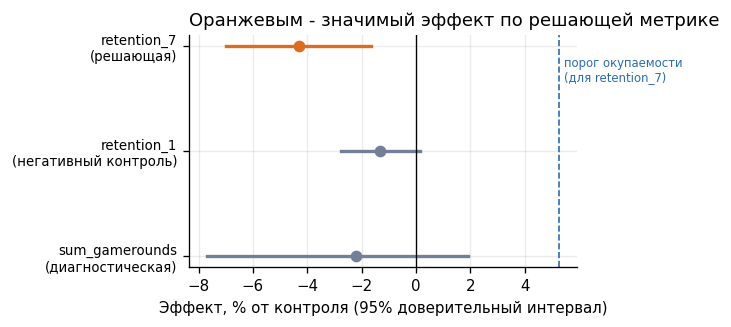

In [16]:
# Эффекты с интервалами на одной картинке (относительные, чтобы метрики были сопоставимы)
fig, ax = plt.subplots(figsize=(5.8, 2.8))
ypos = np.arange(len(summary))[::-1]
for y_, r in zip(ypos, summary.itertuples()):
    lo_rel, hi_rel = r.ci_low / r.control * 100, r.ci_high / r.control * 100
    sig = r.p_value < ALPHA
    color = ORANGE if (sig and r.role == "решающая") else GREY
    ax.plot([lo_rel, hi_rel], [y_, y_], color=color, lw=2)
    ax.plot(r.rel * 100, y_, "o", color=color, ms=6)
ax.axvline(0, color="black", lw=0.8)
ax.axvline(MDE_ABS / base * 100, color=BLUE, ls="--", lw=1)
ax.annotate("порог окупаемости\n(для retention_7)",
            xy=(MDE_ABS / base * 100, ypos.max()), xytext=(3, -6),
            textcoords="offset points", color=BLUE, fontsize=7, va="top")
ax.set_yticks(ypos)
ax.set_yticklabels([f"{r.metric}\n({r.role})" for r in summary.itertuples()], fontsize=8)
ax.set_xlabel("Эффект, % от контроля (95% доверительный интервал)")
ax.set_title("Оранжевым - значимый эффект по решающей метрике", loc="left")
fig.tight_layout()
plt.show()

**Вывод.** `retention_7`: -0.82 п.п., p = 0.0016, интервал целиком ниже нуля
и ниже порога. Две другие метрики незначимы и обе в минус. Независимым подтверждением
это не является, так как метрики считаются по одним игрокам и скоррелированы.

Правдоподобная интерпретация: гейт на 40-м уровне отсеивает часть игроков, которые
иначе вернулись бы через неделю. Проверить её по этим данным нельзя, так как нет сведений
о том, кто и когда столкнулся с гейтом.

## 6. Подглядывание

Решение выше принято по одному чтению полной выборки. Оцениваем цену альтернативы:
A/A-тест без эффекта, 14 ежедневных проверок, считаем долю прогонов, где хотя бы
одна проверка дала p < 0.05.

In [17]:
N_SIM = 4000
N_LOOKS = 14          # две недели ежедневных проверок
p_true = base         # эффекта нет: обе группы с одной и той же долей

# Набор пользователей идёт теми же неравными группами, что и в самом тесте
per_day_a = n_control // N_LOOKS
per_day_b = n_treat // N_LOOKS

stop_early = 0
for _ in range(N_SIM):
    ca = cb = na_ = nb_ = 0
    for _day in range(N_LOOKS):
        ca += RNG_PEEK.binomial(per_day_a, p_true); na_ += per_day_a
        cb += RNG_PEEK.binomial(per_day_b, p_true); nb_ += per_day_b
        _, p_look = proportions_ztest([ca, cb], [na_, nb_])
        if p_look < ALPHA:
            stop_early += 1
            break

fpr_peek = stop_early / N_SIM
peek_se = np.sqrt(fpr_peek * (1 - fpr_peek) / N_SIM)

print(f"Симуляций: {ru(N_SIM)}, проверок в каждой: {N_LOOKS}")
print(f"Доля A/A-тестов, где хотя бы раз увидели p < {ALPHA}: "
      f"{fpr_peek:.1%} ± {peek_se * 100:.1f} п.п.")
print(f"Заявленный уровень значимости: {ALPHA:.0%}")
print(f"Во сколько раз больше заявленного: {fpr_peek / ALPHA:.1f}")

Симуляций: 4 000, проверок в каждой: 14
Доля A/A-тестов, где хотя бы раз увидели p < 0.05: 21.8% ± 0.7 п.п.
Заявленный уровень значимости: 5%
Во сколько раз больше заявленного: 4.4


**Вывод.** Доля ложных срабатываний в разы выше заявленных 5%. Предполагаемая причина: момент остановки выбирается по данным,
и чем больше точек остановки, тем вероятнее попасть на благоприятный шум.

Модель упрощена - равномерный приток, мгновенное измерение, фиксированное число
проверок. Реальное раздутие зависит от правила остановки и графика набора,
поэтому оно сопоставимо с показанным или больше, но точного равенства здесь нет.

## 7. Решение

In [18]:
print("РЕШАЮЩАЯ МЕТРИКА — retention_7")
print(f"  контроль {main_res['control']:.4f} -> тест {main_res['treat']:.4f}")
print(f"  эффект {main_res['diff'] * 100:+.2f} п.п. "
      f"({main_res['rel']:+.1%} относительно контроля)")
print(f"  CI95 [{main_res['ci_low'] * 100:+.2f}; {main_res['ci_high'] * 100:+.2f}] п.п.")
print(f"  p (против нуля)  = {main_res['p_value']:.4f}")
print(f"  p (против порога {MDE_ABS * 100:+.0f} п.п.) = {p_margin:.2e}")
print()
print("НЕГАТИВНЫЙ КОНТРОЛЬ - retention_1")
print(f"  эффект {nc_res['diff'] * 100:+.2f} п.п., p = {nc_res['p_value']:.4f} "
      "(эффекта быть не должно)")
print()
print("ДИАГНОСТИЧЕСКАЯ - sum_gamerounds")
print(f"  эффект {mean_diff:+.1f} раунда, CI95 [{mean_lo:+.1f}; {mean_hi:+.1f}]")
print(f"  Mann-Whitney p = {p_guard_mw:.4f}")
print()
print("САНИТИ")
print(f"  SRM p = {p_srm:.4f} (порог {ALPHA_SRM})")
print(f"  A/A: доля ложных срабатываний {fpr_aa:.1%}, KS p = {ks_p:.3f}")
print()
print("РЕШЕНИЕ: гейт на 40-й уровень не переносить.")

РЕШАЮЩАЯ МЕТРИКА — retention_7
  контроль 0.1902 -> тест 0.1820
  эффект -0.82 п.п. (-4.3% относительно контроля)
  CI95 [-1.33; -0.31] п.п.
  p (против нуля)  = 0.0016
  p (против порога +1 п.п.) = 1.09e-12

НЕГАТИВНЫЙ КОНТРОЛЬ - retention_1
  эффект -0.59 п.п., p = 0.0744 (эффекта быть не должно)

ДИАГНОСТИЧЕСКАЯ - sum_gamerounds
  эффект -1.2 раунда, CI95 [-4.0; +1.0]
  Mann-Whitney p = 0.0502

САНИТИ
  SRM p = 0.0086 (порог 0.01)
  A/A: доля ложных срабатываний 5.7%, KS p = 0.255

РЕШЕНИЕ: гейт на 40-й уровень не переносить.
